# EDA: ข้อมูลราคาตลาด SPY, IEF และ GLD

## วัตถุประสงค์

สำรวจข้อมูลราคาของ ETF ทั้งสามสินทรัพย์ เพื่อทำความเข้าใจคุณภาพข้อมูล ผลตอบแทน ความผันผวน และความสัมพันธ์ระหว่างสินทรัพย์ ก่อนนำข้อมูลไปสร้าง features และโมเดลพยากรณ์ความเสี่ยง

ข้อมูลต้นทางคือ `market_prices_daily.parquet` ที่ผ่าน ingestion pipeline โดยหนึ่งแถวแทนหนึ่งสินทรัพย์ในหนึ่งวันซื้อขาย ช่วงวิเคราะห์และ warm-up อ้างอิง config ของข้อมูลที่โหลด


## 0. Environment และไลบรารีที่ใช้

ติดตั้งจาก **โฟลเดอร์หลักของโปรเจกต์** ก่อนเปิด notebook:

```bash
uv sync --locked --no-dev --group eda
uv run --locked --no-dev --group eda jupyter lab
```

เลือก kernel ของ `.venv` ในโปรเจกต์ หากใช้ pip ให้ติดตั้ง `python -m pip install -r requirements.txt` ใน environment นั้นแทน
คำสั่งติดตั้งอยู่ใน Markdown เพื่อไม่เปลี่ยน environment ระหว่างวิเคราะห์ ไม่ใช้ `!pip install` ภายใน notebook
เซลล์ถัดไปรวม imports และแสดง Python/เวอร์ชันที่ใช้ หากขาดไลบรารีต้องติดตั้งให้ครบก่อนทำต่อ

In [1]:
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandas_market_calendars as mcal
from IPython.display import display

%matplotlib inline

print("Python:", sys.version.split()[0])
print("Kernel executable:", sys.executable)
display(pd.DataFrame(
    [(name, version(name)) for name in (
        "pandas", "numpy", "matplotlib", "pandas-market-calendars",
        "pyarrow", "PyYAML", "ipykernel", "jupyterlab",
    )], columns=["library", "version"]
))

Python: 3.10.21
Kernel executable: D:\New folder (2)\datasci-and-dataen-project\.venv\Scripts\python.exe


,library,version
0,pandas,2.2.3
1,numpy,2.2.6
2,matplotlib,3.10.9
3,pandas-market-calendars,5.5.0
4,pyarrow,25.0.1
5,PyYAML,6.0.3
6,ipykernel,6.31.0
7,jupyterlab,4.6.6


## โหลดข้อมูลและขอบเขตที่คาดหวัง

อ่าน curated และ `config/ingestion.yaml` เพื่อกำหนดช่วงวิเคราะห์ รวมจำนวนวัน warm-up ก่อนวันเริ่มต้นตามปฏิทินตลาด
ใช้ช่วงวันที่ใน config โดยตรง ไม่ใช้วันแรก–วันสุดท้ายของข้อมูลเป็นขอบเขต เพื่อให้ตรวจพบข้อมูลที่หายต้นหรือท้ายช่วงได้
เลือก config ให้ตรงกับชุดข้อมูลที่ต้องการสำรวจ หากข้อมูลยังไม่ครบช่วงที่กำหนด การตรวจจะแสดงวันที่ขาด

In [2]:
# รองรับการเปิด notebook จาก root, notebooks/ หรือโฟลเดอร์ย่อยในโปรเจกต์
project_root = next((
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "config" / "ingestion.yaml").is_file() and (path / "src").is_dir()
), None)
if project_root is None:
    raise FileNotFoundError("เปิด notebook ภายในโฟลเดอร์โปรเจกต์ที่มี config/ingestion.yaml")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.ingestion.config import load_config
from src.eda.quality import inspect_market_prices, add_historical_rv, inspect_historical_rv

config = load_config(project_root / "config" / "ingestion.yaml")
data_path = project_root / "data" / "curated" / "market_prices_daily.parquet"
if not data_path.is_file():
    raise FileNotFoundError(f"ไม่พบ {data_path}; กรุณารัน ingestion pipeline ก่อน")
source_df = pd.read_parquet(data_path)
if source_df.empty:
    raise ValueError("ข้อมูล curated ว่าง; กรุณารัน ingestion pipeline ก่อน")

# หาวันเริ่ม warm-up จากปฏิทินตลาด แทนการเดาจากข้อมูลที่มีอยู่
calendar = mcal.get_calendar(config["calendar"]["market"])
start_date = pd.Timestamp(config["date_range"]["start_date"])
end_date = pd.Timestamp(config["date_range"]["end_date"])
warmup_days = config["date_range"]["warmup_trading_days"]
lookback_years = max(2, warmup_days // 150 + 2)
while True:
    prior_sessions = calendar.schedule(
        start_date=start_date - pd.DateOffset(years=lookback_years),
        end_date=start_date - pd.Timedelta(days=1),
    ).index
    if len(prior_sessions) >= warmup_days:
        break
    lookback_years *= 2
fetch_start = prior_sessions[-warmup_days]
expected_sessions = calendar.schedule(start_date=fetch_start, end_date=end_date).index

print(f"จำนวนแถว: {source_df.shape[0]:,} | จำนวนคอลัมน์: {source_df.shape[1]}")
print("ช่วงที่ควรมีข้อมูล:", fetch_start.date(), "ถึง", end_date.date())
print("จำนวนวันซื้อขายที่ควรมีต่อสินทรัพย์:", len(expected_sessions))
df = source_df.copy()
display(df.head())

จำนวนแถว: 3,948 | จำนวนคอลัมน์: 12
ช่วงที่ควรมีข้อมูล: 2021-06-30 ถึง 2026-09-25
จำนวนวันซื้อขายที่ควรมีต่อสินทรัพย์: 1316


,date,ticker,adjusted_close,high,low,simple_return,log_return,is_anomaly_flagged,is_warmup_buffer,run_id,source_batch_id,ingested_at_utc
0,2021-06-30,GLD,165.630005,166.100006,164.289993,NaN,NaN,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.340704+00:00
1,2021-06-30,IEF,98.787727,98.933147,98.762067,NaN,NaN,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.334702+00:00
2,2021-06-30,SPY,399.087006,399.758274,398.266563,NaN,NaN,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.328193+00:00
3,2021-07-01,GLD,166.199997,166.880005,165.500000,0.003441,0.003435,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.340704+00:00
4,2021-07-01,IEF,98.716690,98.819400,98.579735,-0.000719,-0.000719,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.334702+00:00


## ภาพรวมข้อมูล

ตรวจสอบชนิดข้อมูลและจำนวนค่าที่ไม่ว่างในแต่ละคอลัมน์ จากนั้นสรุปจำนวนแถว ช่วงวันที่ และจำนวนแถว warm-up ของแต่ละสินทรัพย์


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3948 entries, 0 to 3947
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   date                3948 non-null   object             
 1   ticker              3948 non-null   object             
 2   adjusted_close      3948 non-null   float64            
 3   high                3948 non-null   float64            
 4   low                 3948 non-null   float64            
 5   simple_return       3945 non-null   float64            
 6   log_return          3945 non-null   float64            
 7   is_anomaly_flagged  3948 non-null   bool               
 8   is_warmup_buffer    3948 non-null   bool               
 9   run_id              3948 non-null   object             
 10  source_batch_id     3948 non-null   object             
 11  ingested_at_utc     3948 non-null   datetime64[us, UTC]
dtypes: bool(2), datetime64[us, UTC](1)

In [4]:
overview = df.groupby("ticker").agg(
    rows=("date", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
    warmup_rows=("is_warmup_buffer", "sum"),
)
overview


,rows,first_date,last_date,warmup_rows
ticker,,,,
GLD,1316,2021-06-30,2026-09-25,61
IEF,1316,2021-06-30,2026-09-25,61
SPY,1316,2021-06-30,2026-09-25,61


## ตรวจคุณภาพข้อมูลและทวนสูตรผลตอบแทน

ตรวจ schema/types, คีย์ซ้ำ, ค่าว่าง, finite/positive prices, high-low consistency (tolerance 0.0001), flags และวันซื้อขายของทุก ticker ตาม config
คำนวณ simple/log return อิสระจากราคาที่เรียงตามเวลาโดยใช้ NumPy แล้วเทียบด้วย rtol=1e-9 และ atol=1e-12; แถวแรกของแต่ละ ticker ต้องว่างและแถวถัดไปต้อง finite

`issues` นับแถวที่ผิด ยกเว้นรายการ dtype นับคอลัมน์ และ missing sessions นับวันที่ขาด แถวเดียวอาจผิดหลายรายการจึงห้ามรวมเป็นจำนวนข้อมูลเสียทั้งหมด
ตารางแสดงตัวอย่างได้ไม่เกิน 5 รายการต่อ check หากมี FAIL จะหยุดก่อนสร้างสถิติ/กราฟ ไม่แก้หรือเติมข้อมูลเพื่อให้ผ่าน
Anomaly flag เป็น warning สำหรับทบทวนเหตุการณ์จริง ไม่ทำให้หยุดเพียงเพราะ return สูง; ตรวจเฉพาะว่า flag ตรงกับ threshold ใน config

In [5]:
df, quality_report = inspect_market_prices(source_df, config, expected_sessions)
display(quality_report)
if quality_report.status.eq("FAIL").any():
    display(quality_report.loc[quality_report.status.eq("FAIL")])
    raise ValueError("Data quality checks failed; ตรวจ examples ก่อนวิเคราะห์ต่อ")

analysis = df.loc[~df.is_warmup_buffer].copy()
if analysis.empty:
    raise ValueError("ไม่มีข้อมูลในช่วงวิเคราะห์")
print("Analysis rows by ticker:", analysis.groupby("ticker").size().to_dict())
print("Return nulls (warm-up only):")
display(df.groupby("ticker")[["simple_return", "log_return"]].agg(lambda values: values.isna().sum()))
print("Anomaly flags for review:", int(df.is_anomaly_flagged.sum()))

,check,ticker,issues,status,examples
0,numeric_dtypes,ALL,0,PASS,[]
1,boolean_dtypes,ALL,0,PASS,[]
2,valid_session_date,ALL,0,PASS,
3,duplicate_primary_key,ALL,0,PASS,
4,ticker_domain,ALL,0,PASS,
5,required_non_null:ticker,ALL,0,PASS,
6,required_non_null:is_anomaly_flagged,ALL,0,PASS,
7,required_non_null:is_warmup_buffer,ALL,0,PASS,
8,required_non_null:run_id,ALL,0,PASS,
9,required_non_null:source_batch_id,ALL,0,PASS,


Analysis rows by ticker: {'GLD': 1255, 'IEF': 1255, 'SPY': 1255}
Return nulls (warm-up only):


,simple_return,log_return
ticker,,
GLD,1,1
IEF,1,1
SPY,1,1


Anomaly flags for review: 0


## ทวนสูตร RV และความพร้อมของช่วงวิเคราะห์

คำนวณจากข้อมูลรวม warm-up โดยใช้เฉพาะผลตอบแทนย้อนหลังถึงวัน t ตาม feature contract:
`RV(n,t) = sqrt(252/n × sum(r²))` เป็น annualized decimal แบบไม่หักค่าเฉลี่ย

ตรวจอิสระด้วย NumPy dot product ของแต่ละหน้าต่างย้อนหลัง (ไม่ใช้ pandas rolling ในตัวตรวจ) รวมตำแหน่ง warm-up null และกำหนดให้ RV ทุกช่วง 5/20/60 วันในช่วงวิเคราะห์ต้อง finite และไม่ติดลบ
หากไม่ผ่านจะหยุดก่อนสรุปผล

In [6]:
df = add_historical_rv(df)
rv_checks = inspect_historical_rv(df)
display(rv_checks)
if rv_checks.status.eq("FAIL").any():
    raise ValueError("RV formula/readiness checks failed; ตรวจ example_dates ก่อนทำต่อ")
analysis = df.loc[~df.is_warmup_buffer].copy()

,ticker,window,formula_mismatches,invalid_analysis_rows,max_abs_error,status,example_dates
0,GLD,5,0,0,1.110223e-16,PASS,[]
1,GLD,20,0,0,1.110223e-16,PASS,[]
2,GLD,60,0,0,1.110223e-16,PASS,[]
3,IEF,5,0,0,1.283695e-16,PASS,[]
4,IEF,20,0,0,2.775558e-17,PASS,[]
5,IEF,60,0,0,2.775558e-17,PASS,[]
6,SPY,5,0,0,1.207368e-15,PASS,[]
7,SPY,20,0,0,1.110223e-16,PASS,[]
8,SPY,60,0,0,5.551115e-17,PASS,[]


## การกระจายของผลตอบแทน
สรุป log return รายวันในช่วงวิเคราะห์ หน่วยเป็น decimal; kurtosis เป็น excess kurtosis (normal = 0) ค่าปลายสุดเป็นจุดที่ควรตรวจสอบ ไม่ใช่หลักฐานว่าข้อมูลผิด


In [7]:
returns_summary = analysis.groupby('ticker')['log_return'].agg(['count','mean','median','std','min','max','skew'])
returns_summary['kurtosis_excess'] = analysis.groupby('ticker')['log_return'].apply(lambda s: s.kurt())
returns_summary['q01'] = analysis.groupby('ticker')['log_return'].quantile(.01)
returns_summary['q99'] = analysis.groupby('ticker')['log_return'].quantile(.99)
print(returns_summary.round(5).to_string())
print('\nLargest absolute returns:')
print(analysis.loc[analysis.log_return.abs().nlargest(6).index, ['date','ticker','log_return','is_anomaly_flagged']].to_string(index=False))


        count     mean   median      std      min      max     skew  kurtosis_excess      q01      q99
ticker                                                                                                
GLD      1255  0.00070  0.00080  0.01190 -0.10841  0.06165 -0.79971          7.68662 -0.03189  0.03036
IEF      1255 -0.00008 -0.00010  0.00486 -0.01793  0.02228  0.15630          1.10791 -0.01191  0.01273
SPY      1255  0.00049  0.00061  0.01081 -0.06033  0.09986  0.15217          7.92202 -0.02972  0.02566

Largest absolute returns:
      date ticker  log_return  is_anomaly_flagged
2026-01-30    GLD   -0.108412               False
2025-04-09    SPY    0.099863               False
2025-10-21    GLD   -0.066427               False
2026-02-03    GLD    0.061647               False
2025-04-04    SPY   -0.060327               False
2022-11-10    SPY    0.053497               False


## ความผันผวนย้อนหลังและความสัมพันธ์

ใช้ RV ที่ผ่านการทวนสูตรในส่วนก่อนหน้า ส่วน correlation ใช้ log return ของทั้งสาม ETF บนวันซื้อขายเดียวกัน เป็น historical proxy
ตรวจว่าชุดวันที่ครบและไม่มีค่าว่างก่อนคำนวณ เพื่อไม่ใช้คู่สินทรัพย์ที่มีวันสังเกตต่างกัน

In [8]:
wide = df.pivot(index='date', columns='ticker', values='log_return').sort_index()
analysis_wide = wide.loc[analysis.date.min():analysis.date.max()]
if wide.isna().iloc[1:].any().any() or analysis_wide.isna().any().any():
    raise ValueError("Correlation requires aligned complete returns for all assets")
print('RV summary (annualized decimal):')
print(analysis.groupby('ticker')[[f'rv_{n}d' for n in (5,20,60)]].agg(['mean','median','max']).round(4).to_string())
print('\nPearson correlation (analysis period):')
print(analysis_wide.corr().round(3).to_string())
pairs = [('SPY','IEF'),('SPY','GLD'),('IEF','GLD')]
rolling_corr = pd.DataFrame({f'{a}-{b}': wide[a].rolling(20, min_periods=20).corr(wide[b]) for a,b in pairs}).loc[analysis.date.min():analysis.date.max()]
print('\nRolling 20-day correlations:')
print(rolling_corr.agg(['min','median','max']).round(3).to_string())


RV summary (annualized decimal):
         rv_5d                  rv_20d                  rv_60d                
          mean  median     max    mean  median     max    mean  median     max
ticker                                                                        
GLD     0.1635  0.1439  0.9703  0.1715  0.1470  0.5826  0.1742  0.1530  0.4255
IEF     0.0703  0.0637  0.2308  0.0729  0.0674  0.1435  0.0737  0.0702  0.1199
SPY     0.1481  0.1301  0.9097  0.1556  0.1363  0.5243  0.1600  0.1363  0.3394

Pearson correlation (analysis period):
ticker    GLD    IEF    SPY
ticker                     
GLD     1.000  0.300  0.152
IEF     0.300  1.000  0.097
SPY     0.152  0.097  1.000

Rolling 20-day correlations:
        SPY-IEF  SPY-GLD  IEF-GLD
min      -0.798   -0.736   -0.482
median    0.135    0.184    0.380
max       0.884    0.907    0.844


## กราฟประกอบ

ใช้ Matplotlib ที่ติดตั้งจากกลุ่ม dependencies `eda` และ import ไว้บนสุดแล้ว กราฟราคาเริ่มที่ 100 ในช่วงวิเคราะห์ และ RV แสดงเป็นเปอร์เซ็นต์ต่อปี

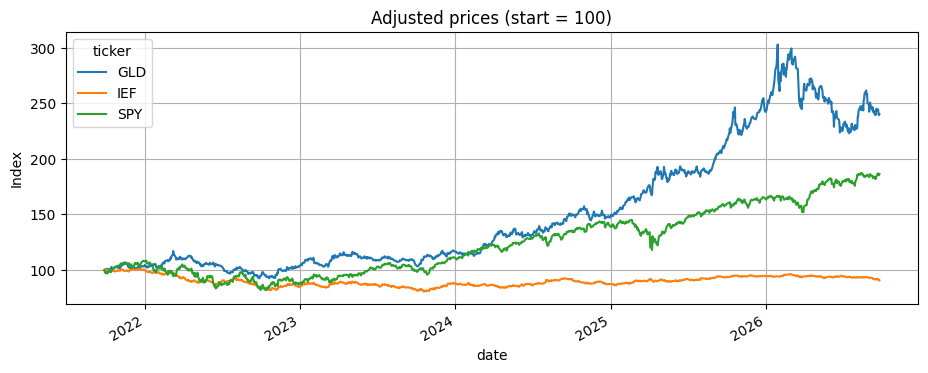

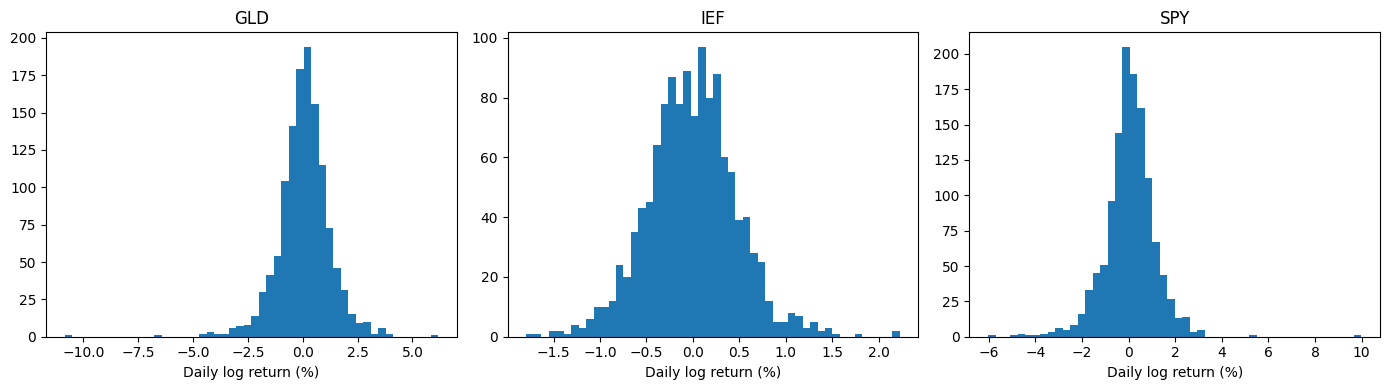

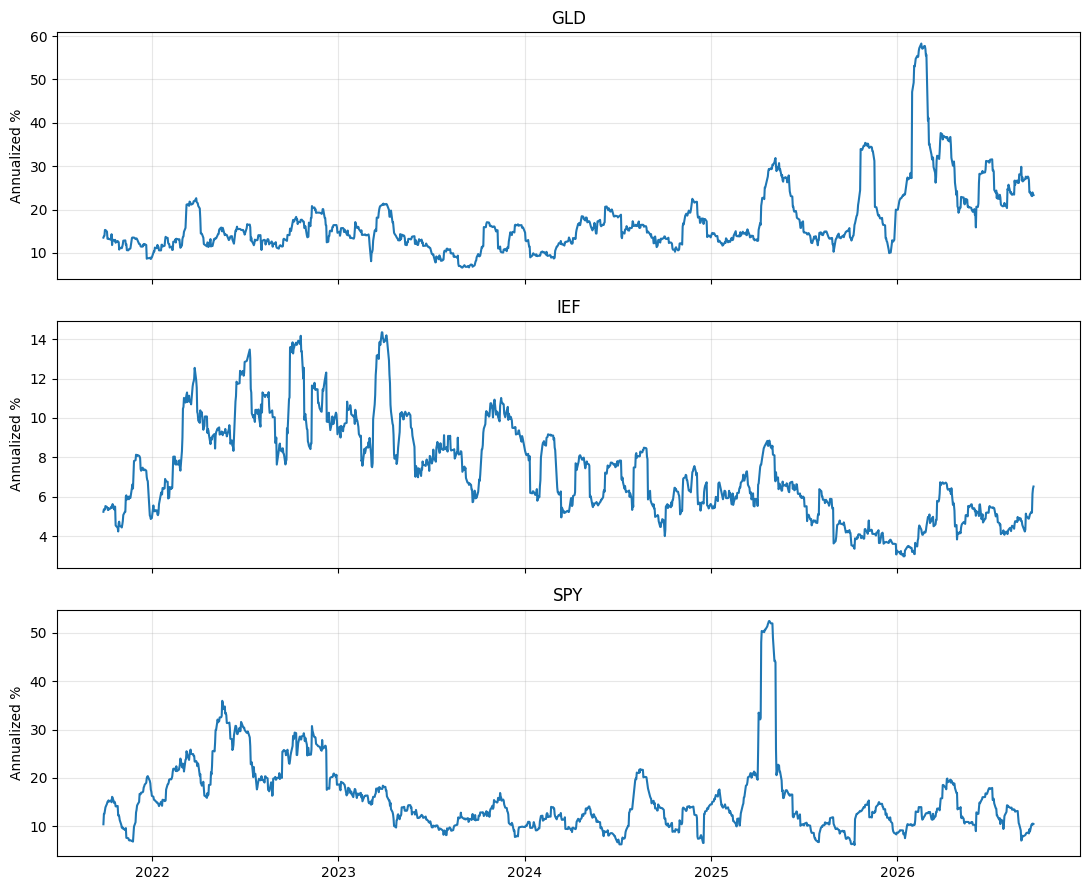

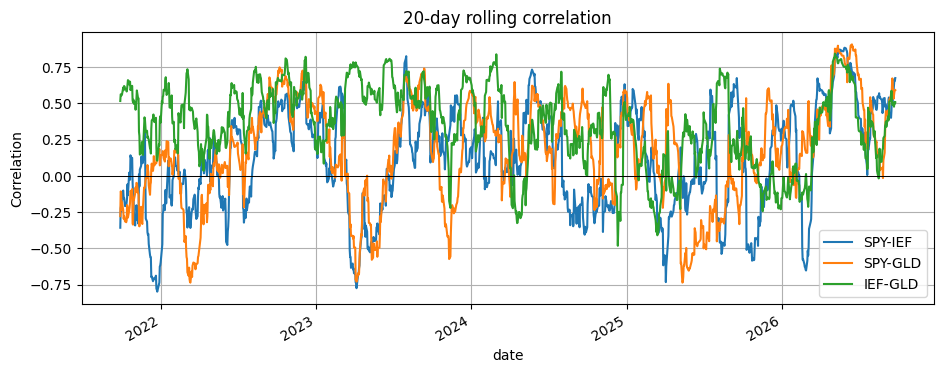

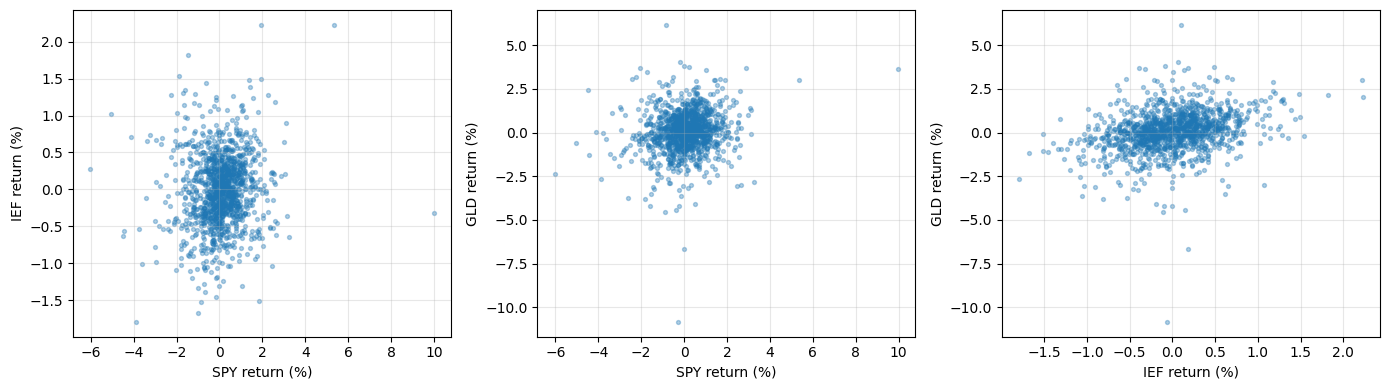

In [9]:
prices = analysis.pivot(index='date', columns='ticker', values='adjusted_close').sort_index()
(prices / prices.iloc[0] * 100).plot(title='Adjusted prices (start = 100)', figsize=(11,4), grid=True)
plt.ylabel('Index'); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, (ticker, g) in zip(axes, analysis.groupby('ticker')):
    ax.hist(g.log_return.dropna() * 100, bins=50)
    ax.set_title(ticker); ax.set_xlabel('Daily log return (%)')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(3, 1, figsize=(11,9), sharex=True)
for ax, (ticker, g) in zip(axes, analysis.groupby('ticker')):
    ax.plot(g.date, g.rv_20d * 100, label='20-day RV')
    ax.set_title(ticker); ax.set_ylabel('Annualized %'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
rolling_corr.plot(figsize=(11,4), title='20-day rolling correlation', grid=True)
plt.axhline(0, color='black', linewidth=.7); plt.ylabel('Correlation'); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, (a,b) in zip(axes, pairs):
    ax.scatter(analysis_wide[a]*100, analysis_wide[b]*100, alpha=.35, s=8)
    ax.set_xlabel(a + ' return (%)'); ax.set_ylabel(b + ' return (%)'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## การนำผลไปใช้
- ตรวจวันผลตอบแทนสุดขั้วกับข้อมูลต้นทางก่อนตัดสินใจจัดการ ไม่ลบข้อมูลโดยอัตโนมัติ
- เปรียบเทียบ RV และ rolling correlation หลายช่วงเวลา เพราะความเสี่ยงและความสัมพันธ์อาจเปลี่ยนได้
- ผลสำรวจทั้งช่วงเป็น descriptive analysis; เกณฑ์ feature/model ต้องพัฒนาจาก training เท่านั้น และแบ่งข้อมูลตามเวลาเพื่อป้องกัน leakage
- Notebook นี้เป็นการสำรวจ ไม่ได้เผยแพร่ feature, correlation หรือ target pipeline; target ต้องใช้ผลตอบแทนอนาคต t+1 ถึง t+5 ตาม contract


## ข้อค้นพบเบื้องต้นจากข้อมูลชุดปัจจุบัน

- ช่วงวิเคราะห์มี 1,255 วันต่อสินทรัพย์ ไม่พบคีย์ซ้ำ วันซื้อขายขาด หรือราคาที่ไม่ผ่านการตรวจเบื้องต้น; return ที่ว่างมี 3 ค่าในช่วง warm-up
- ส่วนเบี่ยงเบนมาตรฐานรายวันของ log return: GLD 1.19%, SPY 1.08%, IEF 0.49%; GLD และ SPY มี excess kurtosis ประมาณ 7.69 และ 7.92 ตามลำดับ แสดงหางหนักเมื่อเทียบกับ normal
- correlation ตลอดช่วงของ SPY–IEF, SPY–GLD และ IEF–GLD เท่ากับ 0.097, 0.152 และ 0.300 แต่ rolling 20 วันเปลี่ยนจากลบเป็นบวกได้มาก จึงไม่ควรสมมติว่าความสัมพันธ์คงที่
- GLD วันที่ 2026-01-30 มี log return ประมาณ -10.84% เป็นจุดที่ควรตรวจสอบแหล่งข้อมูล แม้ไม่ถูก flag ตามเกณฑ์ simple return ±20%
- ข้อค้นพบนี้เป็นการพรรณนาข้อมูลชุดปัจจุบัน ไม่ใช่ผลประเมินโมเดลนอกตัวอย่าง
